# Imports et chargement des csv

# DATASET EVENEMENTS

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

df_evenements = pd.read_csv('../data/raw/Dome_evenements.csv')

print(df_evenements.shape)

print(df_evenements.columns.tolist())

df_evenements.head()


(98, 8)
['evenement_id', 'genre', 'jour_semaine', 'capacite', 'prix_moyen_eur', 'notoriete_artiste', 'billets_vendus', 'date']


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
0,EV320,rap,dim,9800,18.00,26.0,4923.0,2025-11-20
1,EV370,spectacle,mar,15800,74.23,20.0,6051.0,2026-06-08
2,EV377,sport,sam,6500,45.99,53.0,5221.0,2026-07-06
3,EV362,rap,ven,9800,70.96,NaN,6203.0,2026-05-07
4,EV394,sport,dim,9800,46.33,100.0,7196.0,2026-09-12


In [2]:
# Informations générales sur le dataset

print("Shape")
print(df_evenements.shape)

print("\n types des colonnes")
print(df_evenements.dtypes)

print("\n ====================================================================================================================================")


print("\n Stats descriptives")
df_evenements.describe()


Shape
(98, 8)

 types des colonnes
evenement_id             str
genre                    str
jour_semaine             str
capacite               int64
prix_moyen_eur       float64
notoriete_artiste    float64
billets_vendus       float64
date                     str
dtype: object


 Stats descriptives


,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus
count,98.000000,98.000000,96.000000,98.000000
mean,10510.204082,71.712143,42.000000,5512.989796
std,3557.321180,27.453541,28.302501,2020.345089
min,6500.000000,18.000000,5.000000,0.000000
25%,6500.000000,48.482500,21.000000,4354.750000
50%,9800.000000,73.115000,33.500000,5567.000000
75%,15800.000000,90.517500,56.750000,6500.000000
max,15800.000000,137.080000,100.000000,10179.000000


In [3]:
print("Etude de potentielles valeurs manquantes dans le dataset")

print("\n Valeurs manquantes")
display(df_evenements.isnull().sum().sort_values(ascending=False))


Etude de potentielles valeurs manquantes dans le dataset

 Valeurs manquantes


notoriete_artiste    2
evenement_id         0
jour_semaine         0
genre                0
capacite             0
prix_moyen_eur       0
billets_vendus       0
date                 0
dtype: int64

Seule `notoriete_artiste` est incomplète (2 valeurs manquantes sur 98, soit ≈ 2 %) ; toutes les autres colonnes sont complètes.
sous réserve des 3 valeurs à 0, voir étape sur la colonne billets_vendus

In [4]:
print("Etude de potentiels doublons sur le dataset")

print("\n Doublons - lignes entières")
print(df_evenements.duplicated().sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(keep=False)].sort_values(by='evenement_id'))

print("\n ====================================================================================================================================")


print("\n Doublons - même evenement_id")
print(df_evenements.duplicated(subset='evenement_id').sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(subset='evenement_id', keep=False)].sort_values(by='evenement_id'))

print("\n ====================================================================================================================================")



colonnes_sans_id = df_evenements.columns.drop('evenement_id')

print("\n Doublons - même contenu, id différent")
print(df_evenements.duplicated(subset=colonnes_sans_id).sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(subset=colonnes_sans_id, keep=False)].sort_values(by='date'))

Etude de potentiels doublons sur le dataset

 Doublons - lignes entières
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08




 Doublons - même evenement_id
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08




 Doublons - même contenu, id différent
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08


« 2 événements (EV331, EV340) sont présents en double à l’identique. Aucun identifiant n’est en conflit et aucun événement n’est saisi sous deux identifiants. Décision : supprimer les 2 copies lors du preprocessing (98 → 96 événements). »

In [5]:
print("Etudes sur la colonne genre et jour de la semaine")

display(df_evenements['genre'].value_counts(dropna = False))
display(df_evenements['jour_semaine'].value_counts(dropna = False))


Etudes sur la colonne genre et jour de la semaine


genre
concert pop    28
rock           26
rap            14
sport          13
humour          9
spectacle       8
Name: count, dtype: int64

jour_semaine
sam    33
ven    17
jeu    16
mer    13
dim    11
mar     8
Name: count, dtype: int64

Les deux colonnes catégorielles sont propres : aucune valeur manquante, aucune écriture incohérente. On retient deux observations pour l’analyse : les petits effectifs de humour et spectacle, et la sur-représentation du samedi et l’absence du lundi.

In [6]:
# A. Valeurs non entières
print("\n Valeurs non entières")
masque_non_entier = df_evenements['billets_vendus']!=df_evenements['billets_vendus'].round()
print(masque_non_entier.value_counts())
display(df_evenements[masque_non_entier])




 Valeurs non entières
billets_vendus
False    98
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date


« billets_vendus est lue en float parce que le fichier écrit les valeurs avec un .0 ; les 98 valeurs sont entières, la colonne sera convertie en entier au preprocessing. »

In [7]:
# B. Événements à 0 billet
print("\n Événements à 0 billet")
masque_zero = df_evenements['billets_vendus']== 0
print(masque_zero.value_counts())
display(df_evenements[masque_zero])


 Événements à 0 billet
billets_vendus
False    95
True      3
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
46,EV374,concert pop,sam,15800,103.45,17.0,0.0,2026-06-24
55,EV303,rock,sam,9800,48.11,NaN,0.0,2025-09-13
78,EV355,rock,sam,9800,87.13,14.0,0.0,2026-04-09


Constat chiffré (3 événements, leurs identifiants) et hypothèses. La décision finale attendra le croisement avec le fichier des billets.

In [8]:
# inspecter le potentiel depassement billet_vendus/capacité

print("\n Ratio billets/capacité")

masque_depassement= df_evenements['billets_vendus']>df_evenements['capacite']
print(masque_depassement.value_counts())
display(df_evenements[masque_depassement])

print("\n =======================================================")

# Etude de taux de remplissage des stades/salles

taux_de_remplissage = df_evenements['billets_vendus']/df_evenements['capacite']
taux_de_remplissage.describe()


 Ratio billets/capacité
False    98
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date


count    98.000000
mean      0.560887
std       0.221163
min       0.000000
25%       0.401825
50%       0.551785
75%       0.678618
max       1.000000
dtype: float64

In [9]:
print("\n Événements complets (taux = 1)")
masque_complet = taux_de_remplissage == 1
print(masque_complet.value_counts())
display(df_evenements[masque_complet])


 Événements complets (taux = 1)
False    93
True      5
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
37,EV343,spectacle,sam,6500,88.32,74.0,6500.0,2026-02-20
70,EV324,humour,sam,6500,29.54,60.0,6500.0,2025-12-06
83,EV348,sport,sam,9800,21.34,100.0,9800.0,2026-03-12
93,EV383,concert pop,mer,6500,104.41,95.0,6500.0,2026-07-30
94,EV367,spectacle,sam,6500,45.86,38.0,6500.0,2026-05-27


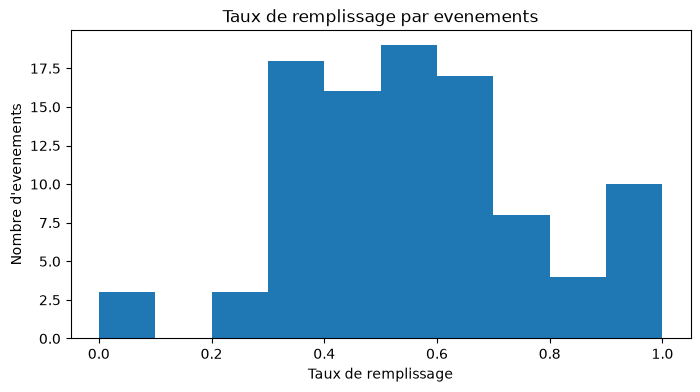

In [14]:

plt.figure(figsize=(8, 4))
plt.hist(taux_de_remplissage, bins=10)
plt.title("Taux de remplissage par evenements")
plt.xlabel("Taux de remplissage")
plt.ylabel("Nombre d'evenements")
plt.show()

# DATASET BILLETS

In [11]:
df_billets = pd.read_csv('../data/raw/Dome_billets.csv')
df_billets.shape

print(df_billets.shape)
print(df_billets.columns.to_list())

df_billets.head()

(820, 12)
['billet_id', 'evenement_id', 'zone', 'prix_paye_eur', 'achat_jours_avant', 'arrivee_min_avant', 'x_salle_m', 'y_salle_m', 'conso_bar_eur', 'age', 'deja_venu', 'revient_saison_suivante']


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,non,oui
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,non,non
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,non,non
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,non,non
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,oui,oui


In [12]:
# Informations générales sur le dataset

print("Shape")
print(df_billets.shape)

print("\n types des colonnes")
print(df_billets.dtypes)

print("\n Valeurs manquantes")
print(df_billets.isnull().sum().sort_values(ascending=False))

print("\n Stats descriptives")
df_billets.describe()


Shape
(820, 12)

 types des colonnes
billet_id                      str
evenement_id                   str
zone                           str
prix_paye_eur              float64
achat_jours_avant          float64
arrivee_min_avant          float64
x_salle_m                  float64
y_salle_m                  float64
conso_bar_eur              float64
age                        float64
deja_venu                      str
revient_saison_suivante        str
dtype: object

 Valeurs manquantes
age                        19
conso_bar_eur              16
billet_id                   0
evenement_id                0
prix_paye_eur               0
zone                        0
achat_jours_avant           0
arrivee_min_avant           0
y_salle_m                   0
x_salle_m                   0
deja_venu                   0
revient_saison_suivante     0
dtype: int64

 Stats descriptives


,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age
count,820.000000,820.000000,820.000000,820.000000,820.000000,804.000000,801.000000
mean,70.104598,42.100000,39.703659,0.491341,0.671707,7.224179,34.314607
std,30.338363,30.410657,23.115070,25.434452,25.012094,7.028390,12.734438
min,0.000000,0.000000,-20.000000,-60.100000,-58.900000,0.000000,12.000000
25%,47.900000,19.000000,23.000000,-15.700000,-16.700000,2.575000,25.000000
50%,69.575000,35.000000,39.000000,0.200000,0.150000,5.955000,34.000000
75%,91.200000,56.000000,56.000000,17.075000,17.350000,9.397500,43.000000
max,174.130000,187.000000,121.000000,61.800000,61.300000,35.760000,82.000000
